<a href="https://colab.research.google.com/github/erickcorrea3092/Cheminformatics-course/blob/main/3_1_Fingerprints_con_RDkit_(FP).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ANTECEDENTES

Primero instalamos la libreria RDKit

In [1]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 20.9 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import seaborn as sn
#---------------------- RDKit packages
from rdkit.Chem import AllChem
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Draw
from rdkit import DataStructs
from rdkit.ML.Cluster import Butina
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator, GetTopologicalTorsionGenerator
#------------------- progress bar
from tqdm import tqdm
#------------------- hide warning
import warnings
warnings.filterwarnings('ignore')

[RDKit Documentation](https://www.rdkit.org/docs/GettingStartedInPython.html#feature-definitions-used-in-the-morgan-fingerprints)


#INTRODUCCIÓN

### En este cuaderno el autor te muestra como generar los siguiente fingerprints
*  Molecular ACCess System keys or MACCS-keys
*   Avalon fingerprint
*   Atom-pair fingerprint
*   Topological-Torsions fingerprint.
*   Morgan fingerprint or Circular Fingerprint
*   RDKit Fingerprint

### Aplicaciones de los fingerprints:

* Búsqueda de estructuras, subestructuras y similitud para la detección de ligandos virtuales a partir de bases de datos de compuestos <br/>
* Aprendizaje automático: relación cuantitativa estructura-actividad (QSAR) y relación cuantitativa estructura-propiedad (QSPR)

<b> ¿Qué son las fingerprints moleculares?</b><br/> Son descriptores moleculares que codifican características/fragmentos moleculares de una molécula en forma de un dígito binario (0 o 1). Entonces, podemos usar huellas dactilares moleculares para realizar cálculos. Un bit está activado o 1 si se encuentra un determinado fragmento en una estructura molecular. <br/>
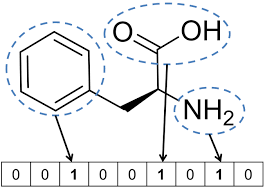

Una representación molecular es una codificación de una estructura química en una forma que sea entendible por un programa computacional. La mayoría de las representaciones tienen propósito(s) concreto(s). Por ejemplo:

Comunicación y análisis cualitativos.
Almacenamiento (data storage).
Búsqueda de estructuras (structure searching).


# Generando algunos Fingerprints Moleculares disponibles en RDKit [RDKit library](https://www.rdkit.org/docs/RDKit_Book.html#additional-information-about-the-fingerprints)


 Referencia del grupo de datos:  [Sandfort et al ](https://www.sciencedirect.com/science/article/pii/S2451929420300851)

## 0. Cargando y renderizando moléculas [referencias](https://colab.research.google.com/notebooks/io.ipynb?hl=es#scrollTo=vz-jH8T_Uk2c)

In [3]:
#Cargamos las datos de una dirección de git hub
dataset = pd.read_csv('https://raw.githubusercontent.com/gashawmg/HOMO-LUMO-Enegry-gap-Prediction/master/Orbital_Energies_input_data.csv')
dataset.head(10) #vemos los primeros diez datos

,SMILES,Energygap
0,Cc1ccc(cc1)C(F)(F)F,197.749421
1,OC(=O)CCCCl,247.493942
2,CC(C)(Oc1ccc(CCNC(=O)c2ccc(Cl)cc2)cc1)C(=O)O,164.712327
3,Nc1ccc(Cl)c(Cl)c1,169.027707
4,C[C@@H](CCO)CCC=C(C)C,209.569808
5,OC(C=C)C=C,210.979194
6,O=N(=O)c1ccc(Cl)c(c1)N(=O)=O,168.833179
7,O=CC1CCCCC1,213.451579
8,COc1ccc(cc1)C#C,171.191985
9,Brc1cncnc1,188.344944


In [4]:
dataset.shape

(2904, 2)

In [5]:
# Incluyamos estructuras 2D  de las moleculas para conocer los datos
# https://github.com/rdkit/rdkit/blob/master/rdkit/Chem/PandasTools.py

from rdkit.Chem import PandasTools
PandasTools.AddMoleculeColumnToFrame(dataset,'SMILES', 'Structure')

,SMILES,Energygap,Structure
0,Cc1ccc(cc1)C(F)(F)F,197.749421,
1,OC(=O)CCCCl,247.493942,
2,CC(C)(Oc1ccc(CCNC(=O)c2ccc(Cl)cc2)cc1)C(=O)O,164.712327,
3,Nc1ccc(Cl)c(Cl)c1,169.027707,
4,C[C@@H](CCO)CCC=C(C)C,209.569808,
...,...,...,...
2899,C(CP(c1ccccc1)c1ccccc1)P(c1ccccc1)c1ccccc1,168.649319,
2900,Brc1cccc2sccc12,162.928319,
2901,CCO[C@H]1C=Cc2ccccc2N1C(=O)OCC,165.098245,
2902,s1ccc2ccccc12,167.958431,

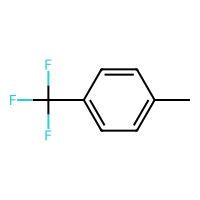
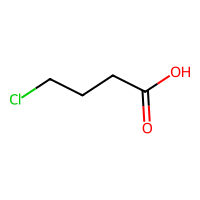
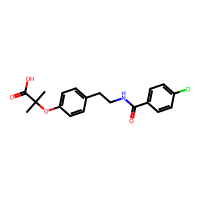
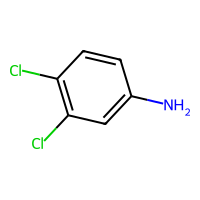
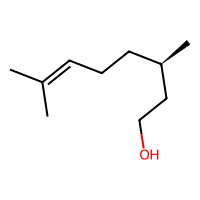
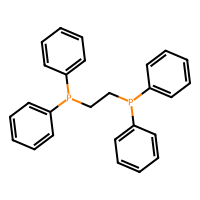
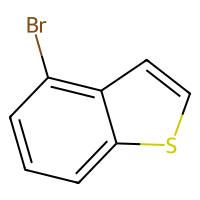
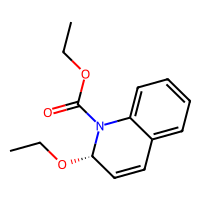
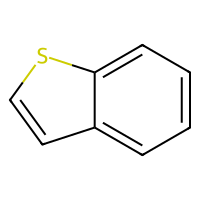
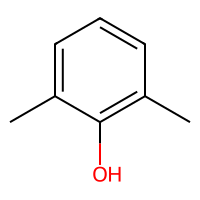

In [6]:
dataset

In [7]:
dataset.shape

(2904, 3)

In [8]:
dataset.head(4)

,SMILES,Energygap,Structure
0,Cc1ccc(cc1)C(F)(F)F,197.749421,<rdkit.Chem.rdchem.Mol object at 0x7d5c4b260580>
1,OC(=O)CCCCl,247.493942,<rdkit.Chem.rdchem.Mol object at 0x7d5c4b260f20>
2,CC(C)(Oc1ccc(CCNC(=O)c2ccc(Cl)cc2)cc1)C(=O)O,164.712327,<rdkit.Chem.rdchem.Mol object at 0x7d5c4b260f90>
3,Nc1ccc(Cl)c(Cl)c1,169.027707,<rdkit.Chem.rdchem.Mol object at 0x7d5c4b261a10>


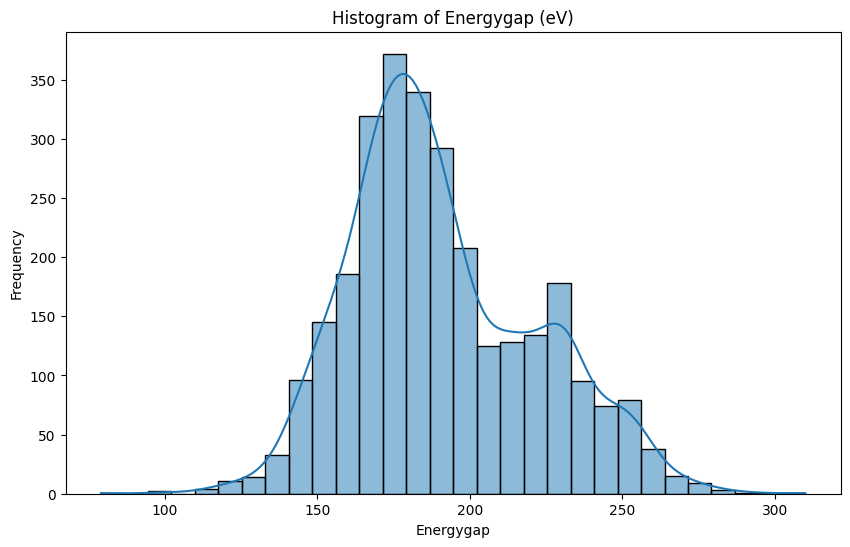

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(dataset.Energygap, bins=30, kde=True)
plt.title('Histogram of Energygap (eV)')
plt.xlabel('Energygap')
plt.ylabel('Frequency')
plt.show()

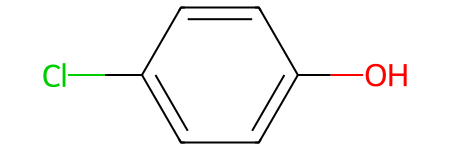

In [10]:
dataset.Structure[67]

In [11]:
dataset.shape

(2904, 3)

En la celda pasada solo vimos los diez primeros datos, veamos todos los datos

Este código utiliza la librería RDKit para visualizar un subconjunto de moléculas de tu dataset en una cuadrícula. Aquí está el desglose de lo que hace cada parte:

`from rdkit.Chem import Draw`: Importa la función Draw del módulo Chem de RDKit, que se utiliza para renderizar moléculas.


`Draw.MolsToGridImage()`: Esta es la función principal que toma una lista de objetos de molécula y los organiza en una imagen de cuadrícula.

Los argumentos que recibe son:
`[x for x in dataset["Structure"]][20:56]`: Esto crea una lista de objetos de molécula. Está tomando los objetos Mol de la columna 'Structure' de tu dataset, específicamente desde el índice 20 hasta el 55 (56 no incluido).

`maxMols=100`: Establece el número máximo de moléculas a mostrar en la cuadrícula. Aunque aquí se pasan 36 moléculas, este parámetro sirve como un límite superior.

`legends=['Energygap: ' + str(x) for x in dataset.Energygap]`: Genera una lista de leyendas para cada molécula. Cada leyenda mostrará el valor de 'Energygap' correspondiente a esa molécula.

`subImgSize=(650,650)`: Define el tamaño de cada imagen individual de la molécula dentro de la cuadrícula, en píxeles.

`molsPerRow=3`: Especifica que se deben mostrar 3 moléculas por fila en la imagen de la cuadrícula.

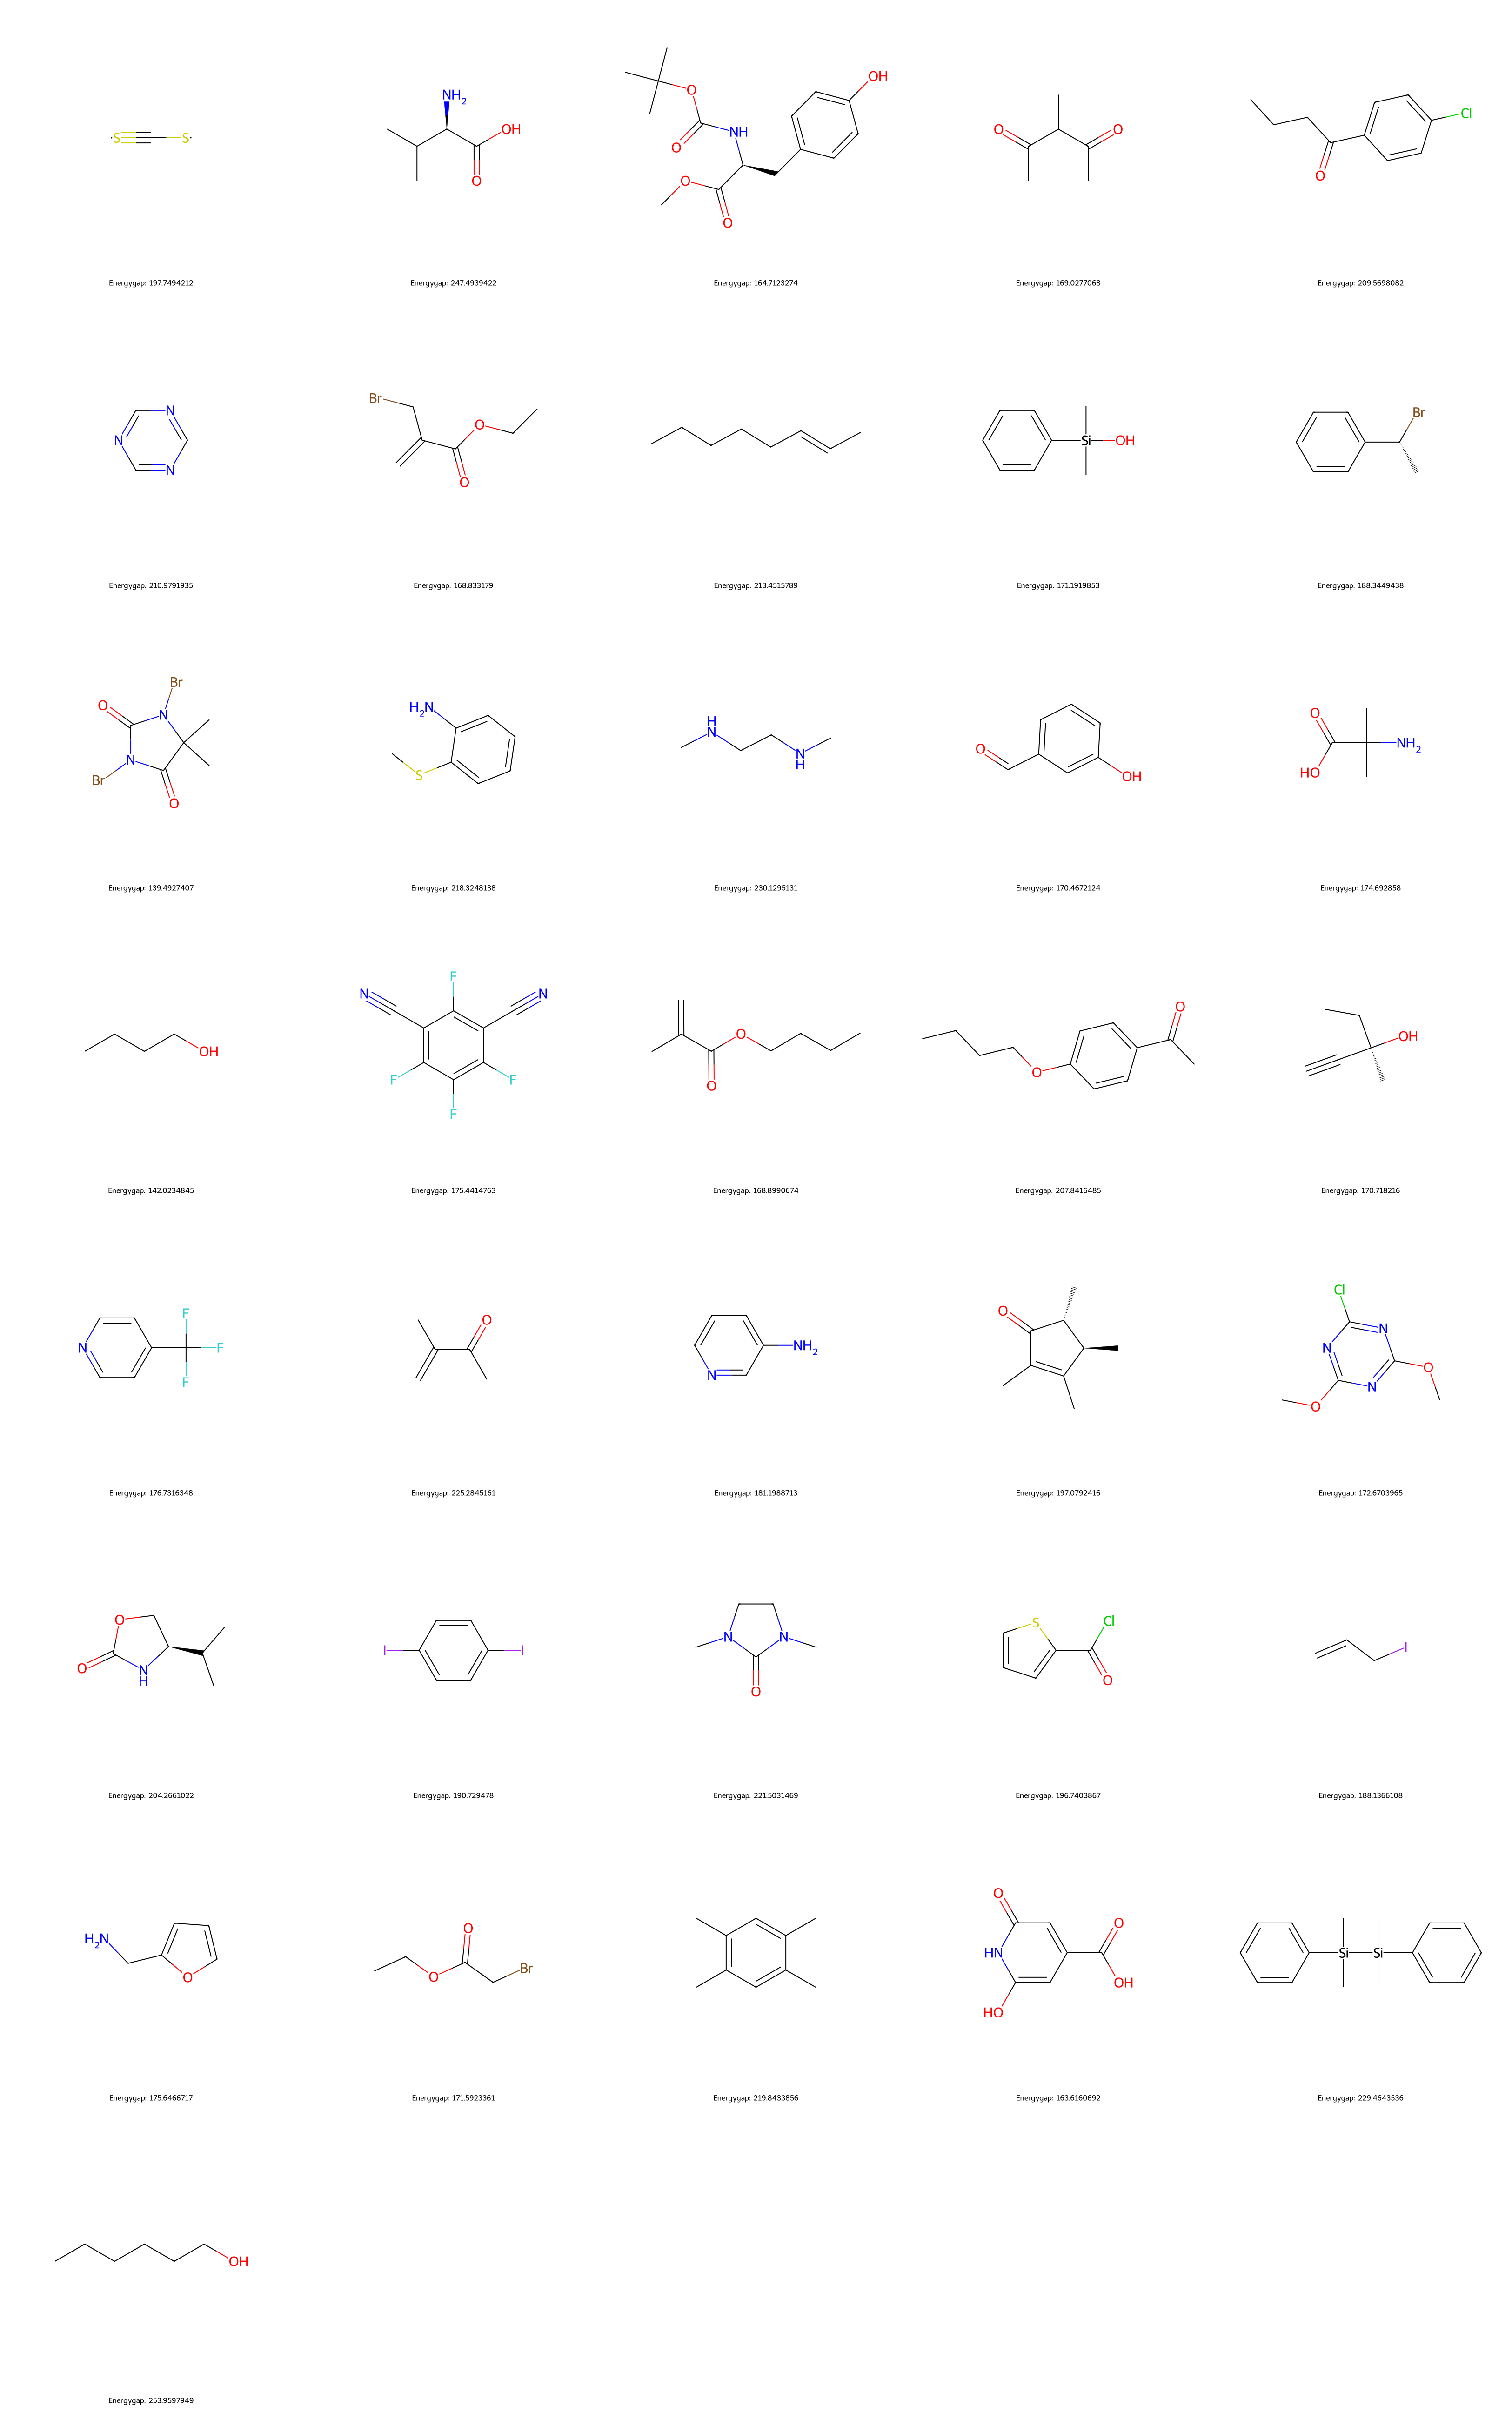

In [12]:
from rdkit.Chem import Draw
Draw.MolsToGridImage([x for x in dataset["Structure"]][20:56],
                     maxMols=100,
                     legends=['Energygap: ' + str(x) for x in dataset.Energygap],
                     subImgSize=(650,650), molsPerRow=5)

Podemos renderizar solo uno de las moléculas con la posición que ocupa en dataset

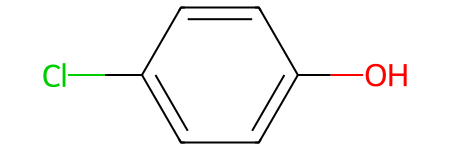

In [13]:
dataset.Structure[67]

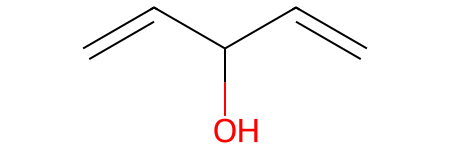

In [14]:
dataset.Structure[5]

Podemos renderizar directamente desde un codigo SMILES

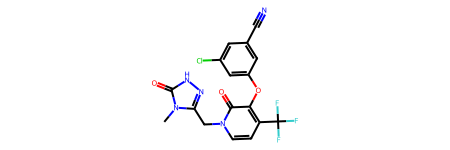

In [15]:
from rdkit import Chem
doravirine = Chem.MolFromSmiles('Cn1c(n[nH]c1=O)Cn2ccc(c(c2=O)Oc3cc(cc(c3)Cl)C#N)C(F)(F)F')
doravirine

##1. Calculando Fingerprints **MACCS** keys


Las MACCS keys, o "claves del Sistema de Acceso Molecular" (del inglés Molecular ACCess System), son uno de los fingerprints más antiguos y simples en quimioinformática. Fueron desarrolladas por MDL (ahora parte de Dassault Systèmes) en los años 80 para bases de datos químicas. Es como un cuestionario con 166 preguntas sí/no sobre la molécula. Cada pregunta corresponde a una subestructura química predefinida, y cada respuesta es un bit en el fingerprint.

e define un conjunto fijo de 166 subestructuras comunes (llamadas "keys" o claves). Por ejemplo:
¿Hay un anillo aromático? (Sí en benceno).
¿Hay menos de 3 oxígenos?
¿Hay un enlace S-S (azufre-azufre)?
¿Hay un halógeno unido a un carbono?
Estas no son aleatorias; están basadas en patrones frecuentes en compuestos orgánicos. Para una molécula dada, se verifica si cada subestructura está presente (bit 1) o no (bit 0). El fingerprint resultante es un vector binario de 166 bits (aunque a veces se usa una versión extendida).

Ventajas: Simple, rápido de calcular, y bueno para subestructura searching (buscar si una molécula contiene un patrón específico). Es interpretable, lo que ayuda en educación o cuando necesitas explicar por qué dos moléculas son similares.


Desventajas: Limitado a solo 166 características predefinidas, así que ignora subestructuras raras o complejas. No captura bien la topología (conexiones) detallada.


Aplicaciones: Usado en bases de datos como PubChem para filtros rápidos. Usados para comparar bibliotecas de compuestos y encontrar análogos de un compuesto conocido.

Vamos a generar los MACCS (Molecular ACCess System) keys (claves) para el compesto de la población 67

In [16]:
from rdkit.Chem import MACCSkeys # importamos la libreria
Mkeys_67 = MACCSkeys.GenMACCSKeys(dataset.Structure[67]) #Calculamos los Keys para el compuesto de la posición [67].
print(np.array(Mkeys_67))# Usamos numpy array para ver los bits ON (1) y OFF (0)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0
 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 0
 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 1 1 1 0]


Vamos a generar los MACCS (Molecular ACCess System) keys (claves) para el compesto de la población 5

In [17]:
from rdkit.Chem import MACCSkeys # importamos la libreria
Mkeys_5 = MACCSkeys.GenMACCSKeys(dataset.Structure[5]) #Calculamos los Keys para el compuesto de la posición [5].
# Usamos numpy array para ver los bits On (1) y Off (0)
print(np.array(Mkeys_5))

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 0]


In [18]:
Mkeys_5 == Mkeys_67

False

In [19]:
print(len(Mkeys_67))
print(len(Mkeys_5))

167
167


In [20]:
print(np.array(Mkeys_67).shape)
print(np.array(Mkeys_5).shape)

(167,)
(167,)


Accedamos a los índices de bits ON

In [21]:
len(tuple(Mkeys_67.GetOnBits()))

14

In [22]:
#Para la molécula 67
# imprimimos bits On
print("Index of On bits:",tuple(Mkeys_67.GetOnBits()))
# how many bits are On?
print("Number of On bits: ",len(Mkeys_67.GetOnBits()))

Index of On bits: (87, 103, 107, 113, 127, 134, 139, 143, 152, 157, 162, 163, 164, 165)
Number of On bits:  14


In [23]:
#Para la molécula 5
# print On bits
print("Index of On bits:",tuple(Mkeys_5.GetOnBits()))
# how many bits are On?
print("Number of On bits: ",len(Mkeys_5.GetOnBits()))

Index of On bits: (34, 99, 139, 152, 157, 164)
Number of On bits:  6


In [24]:
#Para la molécula 5
print("Index of On bits:", np.nonzero(Mkeys_5))
print("Number of On bits: ", np.count_nonzero(Mkeys_5))

Index of On bits: (array([ 34,  99, 139, 152, 157, 164]),)
Number of On bits:  6


##2. Calculando Fingerprints **Avalon**

Los Avalon fingerprints provienen de la toolkit Avalon, desarrollada por Novartis y ahora integrada en RDKit. Son una evolución de fingerprints basados en caminos (paths), similares a los Daylight fingerprints (otro estándar clásico). Piensa en ellos como un "mapa de rutas" dentro de la molécula.

Enumeran todos los caminos lineales de átomos (secuencias conectadas por enlaces) hasta una longitud máxima (por defecto, 8-10 átomos); cada camino se describe por tipos de átomos, tipos de enlaces y ramificaciones. Luego, estos caminos se "hashean" (se convierten en un número único usando una función matemática) y se mapean a bits en un vector fijo (típicamente 1024 o 4096 bits). El hashing evita colisiones (dos caminos diferentes mapeando al mismo bit) lo mejor posible.
Son fingerprints hashed y de longitud fija, lo que los hace eficientes para almacenamiento. Incluyen información topológica (distancias entre átomos) y pueden capturar características como anillos o ramificaciones.

Ventajas: Más flexibles que MACCS porque no dependen de subestructuras predefinidas; generan características dinámicamente. Buenos para similitud general y escalan bien con moléculas grandes.


Desventajas: El hashing puede causar colisiones (pérdida de información), y no son tan interpretables como MACCS (no sabes exactamente qué significa cada bit).


Aplicaciones: Útiles en machine learning para QSAR (Quantitative Structure-Activity Relationship, predecir actividad biológica basada en estructura). Se suelen usar para clustering de moléculas en un dataset de compuestos.

Avalon utiliza un generador de huellas dactilares que enumera ciertas rutas y clases de características del gráfico molecular.[reference](https://pubs.acs.org/doi/pdf/10.1021/ci050413p)

In [25]:
# Calculate Avalon fingerprints
from rdkit.Avalon import pyAvalonTools
Av_67 = pyAvalonTools.GetAvalonFP(dataset.Structure[67], nBits=512)
print(np.array(Av_67))

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0
 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 

In [26]:
# print On bits
print("Index of On bits:",tuple(Av_67.GetOnBits()))
# how many bits are On?
print("Number of On bits: ",len(Av_67.GetOnBits()))

Index of On bits: (45, 51, 67, 92, 93, 137, 138, 157, 194, 201, 253, 266, 286, 290, 293, 294, 305, 309, 317, 329, 334, 341, 343, 351, 358, 365, 442, 455, 456, 464, 478)
Number of On bits:  31


In [27]:
Av_5 = pyAvalonTools.GetAvalonFP(dataset.Structure[5], nBits=512)
print(np.array(Av_5))

[0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 0 0
 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 1 0 0 

In [28]:
# print On bits
print("Index of On bits:",tuple(Av_5.GetOnBits()))
# how many bits are On?
print("Number of On bits: ",len(Av_5.GetOnBits()))

Index of On bits: (10, 18, 35, 67, 181, 189, 198, 201, 208, 258, 298, 324, 327, 328, 334, 375, 448, 479, 490, 505)
Number of On bits:  20


##3.Atom-Pairs Fingerprint

Estos fingerprints, propuestos por Carhart et al. en 1985, se centran en pares de átomos y sus distancias topológicas (número de enlaces entre ellos).
____
______

Para cada par de átomos, se codifica: tipo de átomo 1, tipo de átomo 2, y la distancia topológica mínima entre ellos (por ejemplo, 1 para adyacentes, 2 para separados por un enlace, etc.). Esto se hashea y se mapea a bits en un vector (típicamente 1024-8192 bits). Hay versiones counted (cuenta cuántas veces ocurre un par) o binary (solo presencia/ausencia).
Ignora la geometría 3D, solo usa topología 2D (grafo molecular).

Ventajas: Captura relaciones a larga distancia, bueno para similitud estructural donde la conectividad importa más que subestructuras específicas. Resistente a pequeñas variaciones.


Desventajas: Puede ser sensible a moléculas grandes (muchos pares), y el hashing causa colisiones. No captura torsiones o ángulos.


Aplicaciones: Excelente para diversidad en bibliotecas químicas.

[Atom-pair implementation in RDKit](https://github.com/rdkit/rdkit/blob/master/rdkit/Chem/AtomPairs/Pairs.py)


In [29]:
from rdkit.Chem.rdFingerprintGenerator import GetAtomPairGenerator

atom_pair = GetAtomPairGenerator(fpSize=512)
print("AtomPairGenerator initialized successfully.")

AtomPairGenerator initialized successfully.


In [30]:
from rdkit.Chem import rdMolDescriptors
AP_67 = atom_pair.GetFingerprint(dataset.Structure[67])
print(np.array(AP_67))

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1
 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 1
 0 0 0 1 1 1 0 0 0 0 0 0 

In [31]:
# Imprimiendo datos de bits ON
print("Índice de bits ON:",tuple(AP_67.GetOnBits()))
# how many bits are On?
print("Número de bits ON: ",len(AP_67.GetOnBits()))

Índice de bits ON: (32, 33, 36, 112, 160, 161, 188, 220, 221, 224, 225, 226, 240, 312, 313, 352, 440, 441, 472, 473, 480, 484, 485, 486, 508, 509)
Número de bits ON:  26


In [32]:
AP_5 = atom_pair.GetFingerprint(dataset.Structure[5])
print(np.array(AP_5))

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 

In [33]:
# Imprimiendo datos de bits ON
print("Índice de bits ON:",tuple(AP_5.GetOnBits()))
# how many bits are On?
print("Número de bits ON: ",len(AP_5.GetOnBits()))

Índice de bits ON: (128, 204, 205, 220, 228, 229, 312, 313, 412, 413, 440, 441, 460, 461, 480)
Número de bits ON:  15


##4. Topological-Torsions Fingerprint

Desarrollados por Nilakantan et al. en 1987, estos se enfocan en "torsiones", que son secuencias de cuatro átomos consecutivos (como un "giro" en la cadena). Es similar a atom pairs, pero con más contexto.

Identifica todas las secuencias de cuatro átomos conectados (A-B-C-D), codificando tipos de átomos y tipos de enlaces entre ellos. Ignora hidrógenos usualmente. Luego, hashea estas torsiones y las mapea a bits (longitud típica 1024-4096).
Basado en topología, no 3D. Para benceno, las torsiones serían ciclos como C-C-C-C aromáticos, activando bits para patrones planares.

Ventajas: Captura estereoquímica implícita y conformaciones locales, bueno para distinguir isómeros conformacionales. Complementa bien a atom pairs.

Desventajas: Limitado a secuencias lineales de 4 átomos, ignora estructuras ramificadas complejas o distancias largas.



Aplicaciones: Usado en predicción de propiedades físicas como solubilidad. Útil para cribado virtual.

In [34]:
# Calculate Topological-Torsions fingerprints
var = GetTopologicalTorsionGenerator(fpSize=512)
TT = var.GetFingerprint(dataset.Structure[67])
print(np.array(TT))

[1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 

In [35]:
# print On bits
print("Index of On bits:",tuple(TT.GetOnBits()))
# how many bits are On?
print("Number of On bits: ",len(TT.GetOnBits()))

Index of On bits: (0, 1, 128, 129, 356, 357, 380, 381, 382)
Number of On bits:  9


## 5. Calculando los Fingerprints Morgan (Fingerprints Circulares)

Estos son de los más populares hoy en día, basados en el algoritmo de Morgan de 1965, pero modernizados como Extended-Connectivity Fingerprints (ECFP) por Rogers y Hahn en 2010. Piensa en ellos como "círculos" expandiéndose desde cada átomo.

Para cada átomo, se considera su "entorno circular" hasta un radio dado (por ejemplo, radio 2 significa 2 enlaces de distancia). Se codifica el átomo central, sus vecinos, sus vecinos de vecinos, etc., incluyendo tipos, enlaces y ramificaciones. Todo se hashea y se mapea a bits (longitud común 1024-2048). El radio define la "profundidad": ECFP4 es radio 2.


Ventajas: Muy efectivo para similitud, captura subestructuras locales y globales. Escalable y usado en deep learning.

Desventajas: Colisiones en hashing, y para radio pequeño, ignora estructuras grandes.



Aplicaciones: Estándar en virtual screening y AI para química (ej. en AlphaFold o modelos de toxicidad). Ideal para proyectos de machine learning con datasets como ChEMBL.

En cafeína, capturaría los anillos purínicos con radios que abarcan nitrógenos y oxígenos.

Reference [RDKit blog](https://rdkit.blogspot.com/2018/10/using-new-fingerprint-bit-rendering-code.html)


In [36]:
onbits_67 = {} #creamos un diccionario
mf_67 = AllChem.GetMorganFingerprintAsBitVect(dataset.Structure[67], 2, nBits=512, bitInfo = onbits_67)
print(np.array(mf_67))

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 

[01:55:46] DEPRECATION WARNING: please use MorganGenerator


In [37]:
# Imprimiendo los bits ON
print("Índice de bits ON:",tuple(mf_67.GetOnBits()))
# how many bits are On?
print("Número de bits ON: ",len(mf_67.GetOnBits()))

Índice de bits ON: (46, 49, 66, 147, 214, 216, 233, 242, 289, 295, 304, 337, 356)
Número de bits ON:  13


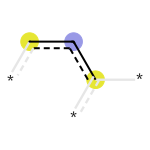

In [38]:
# ¿Cuál es el fragmento o la caracteristica que hace que el bit sea ON?
Draw.DrawMorganBit(dataset.Structure[67], 214, onbits_67)

El término **renderización** (del inglés rendering) es un anglicismo para representación gráfica, usado en la jerga informática para referirse al proceso de generar imagen fotorrealista, o no, a partir de un modelo 2D o 3D (o en lo que colectivamente podría llamarse un archivo de escena) por medio de programas informáticos

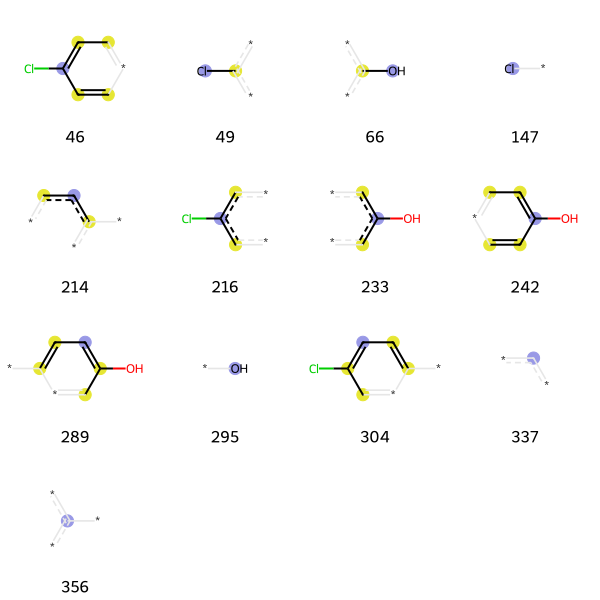

In [39]:
#Renderiza todos los fragmentos o características que son responsables de hacer bits ON
all_fragments = [(dataset.Structure[67], x, onbits_67) for x in mf_67.GetOnBits()]
Draw.DrawMorganBits(all_fragments[:],molsPerRow=4, legends=[str(x) for x in mf_67.GetOnBits()][:])

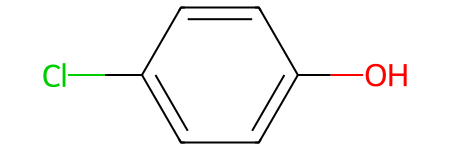

In [40]:
dataset.Structure[67]

In [41]:
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator

# --- Using MorganGenerator (does not directly populate bitInfo) ---
# Initialize the Morgan fingerprint generator
morgan_gen = GetMorganGenerator(radius=2, fpSize=512)

# # Generate the Morgan fingerprint. Note: bitInfo is not a direct parameter for this method.
mf_68 = morgan_gen.GetFingerprint(dataset.Structure[67])
print("Morgan Fingerprint (from MorganGenerator):")

print(np.array(mf_68))


# Generate the Morgan fingerprint. Note: bitInfo is not a direct parameter for this method.
mf_5 = morgan_gen.GetFingerprint(dataset.Structure[5])
print("Morgan Fingerprint (from MorganGenerator):")
print(np.array(mf_5))

Morgan Fingerprint (from MorganGenerator):
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 

###Ahora te toca generar los Fingerprints Morgan para el compuesto de la posición 278, 2005, 420


In [42]:
onbits_MOL = {} #creamos un diccionario
mf_MOL = AllChem.GetMorganFingerprintAsBitVect(dataset.Structure[420], 2, nBits=512, bitInfo=onbits_MOL)
print(np.array(mf_5))

[0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 

[01:55:46] DEPRECATION WARNING: please use MorganGenerator


In [43]:
# Imprimiendo los bits ON
print("Índice de bits ON:",tuple(mf_MOL.GetOnBits()))
# how many bits are On?
print("Número de bits ON: ",len(mf_MOL.GetOnBits()))

Índice de bits ON: (1, 80, 96, 117, 138, 165, 175, 201, 227, 266, 295, 308, 347, 381, 389)
Número de bits ON:  15


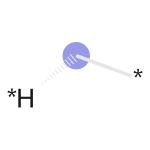

In [44]:
# ¿Cuál es el fragmento o la caracteristica que hace que el bit sea ON?
Draw.DrawMorganBit(dataset.Structure[420], 80, onbits_MOL)

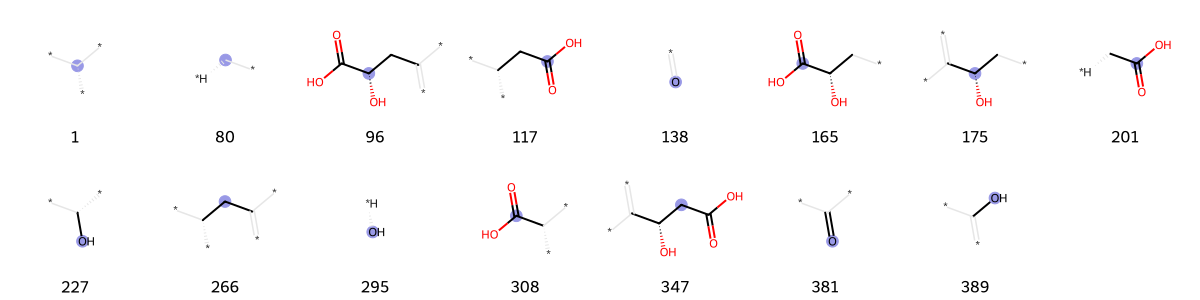

In [45]:
# Render all the fragments or features that are responsible for making ON bits
all_fragments = [(dataset.Structure[420], x, onbits_MOL) for x in mf_MOL.GetOnBits()]
Draw.DrawMorganBits(all_fragments[:],molsPerRow=8, legends=[str(x) for x in mf_MOL.GetOnBits()][:])

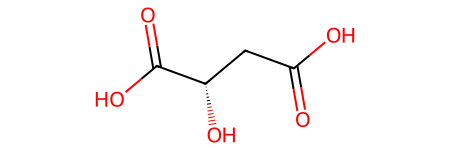

In [46]:
dataset.Structure[420]

<div style= "background-color: lightcyan; border-style:dotted;text-align:left;color:blue;font-size:25px;border-radius: 10px;padding: 20px 20px;">
6. RDKit Fingerprint
</div>

Basadas en subestructuras predefinidas por RDKit.  A diferencia de los fingerprints circulares como los de Morgan, que exploran el entorno de los átomos de forma iterativa, los RDKit fingerprints se basan en una biblioteca de subgrafos (patrones) predefinidos. El algoritmo considera todos los subgrafos de hasta 7 enlaces, que pueden ser lineales o incluir estructuras cíclicas (anillos).

Los parámetros clave que se pueden ajustar incluyen:

`fpSize`: El tamaño total del vector de huella dactilar (número de bits). Un tamaño mayor reduce las colisiones de bits (diferentes características mapeadas al mismo bit).

`minPath` y `maxPath`: La longitud mínima y máxima de las rutas/subgrafos moleculares que se consideran para generar los bits.

`branchedPaths`: Un booleano que determina si se incluyen rutas ramificadas además de las lineales.

In [47]:
rdkbi = {}
Rdk = AllChem.RDKFingerprint(dataset.Structure[2005], maxPath=5, fpSize=512, bitInfo=rdkbi)
# print(np.array(AllChem.RDKFingerprint(mol=dataset.Structure[0], maxPath=5, fpSize=512)))
print(np.array(Rdk))

[0 0 1 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 1 0 0 0 0 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0
 1 1 0 1 0 1 0 0 1 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1 0 1 1 0
 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 0 1 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1
 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 

In [48]:
# print On bits
print("Index of On bits:",tuple(Rdk.GetOnBits()))
# how many bits are On?
print("Number of On bits: ",len(Rdk.GetOnBits()))

Index of On bits: (2, 4, 6, 13, 20, 25, 62, 70, 82, 95, 96, 97, 103, 108, 131, 138, 150, 161, 179, 194, 207, 218, 248, 259, 260, 262, 264, 267, 268, 272, 280, 290, 291, 293, 294, 300, 302, 309, 319, 323, 326, 329, 330, 353, 360, 369, 372, 379, 397, 398, 424, 454, 462, 463, 465, 473, 498, 501)
Number of On bits:  58


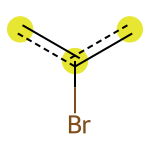

In [49]:
# Visualize a fragment using index of ON bit
Draw.DrawRDKitBit(dataset.Structure[2005],150,rdkbi)

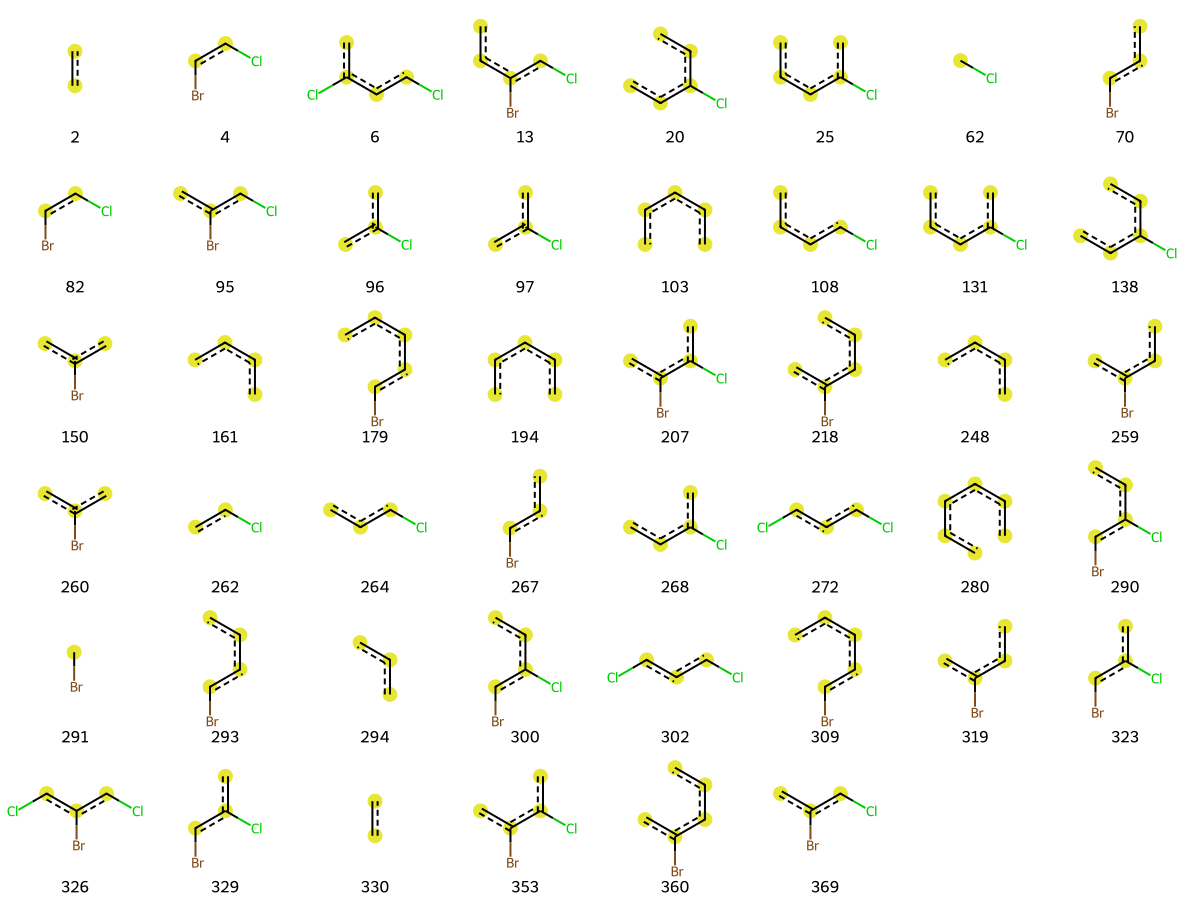

In [50]:
# Visualize more fragments
fragments = [(dataset.Structure[2005], x, rdkbi) for x in rdkbi]
Draw.DrawRDKitBits(fragments[:46],molsPerRow=8,legends=[str(x) for x in rdkbi][:46])

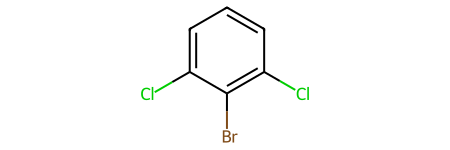

In [51]:
dataset.Structure[2005]

En resumen, cada fingerprint tiene su nicho: MACCS para simplicidad, Avalon para paths generales, Atom Pair para distancias, Torsion para giros locales, y Morgan para entornos circulares.

#Generating  Fingerprints for Multiple Molecules

In [52]:
# function definition
def generate_fpts(data):
    # create empty lists to store fingerprints

    # Morgan fingerprint
    Mfpts = []

    # Avalon fingerprint
    Avfpts = []

    # Topological Torsion fingerprint
    TT_fpts = []

    # Initialize fingerprint generators
    morgan_gen = GetMorganGenerator(radius=2, fpSize=2048)
    topological_torsion_gen = GetTopologicalTorsionGenerator(fpSize=2048)

    for mol in tqdm(data):

        # Calculate Morgan fingerprints and append to the empty list above
        mfpt = morgan_gen.GetFingerprint(mol)
        Mfpts.append(mfpt)

        # Calculate Avalon fingerprints and append to the empty list above
        Avfpt = pyAvalonTools.GetAvalonFP(mol, nBits=2048)
        Avfpts.append(Avfpt)

        #calculate TopologicalTorsion fingerprints and append to the empty list above
        TT_fpt = topological_torsion_gen.GetFingerprint(mol)
        TT_fpts.append(TT_fpt)

    return np.array(Mfpts), np.array(Avfpts), np.array(TT_fpts)

In [53]:
# function call
mfpts, Avfpts, TT_fpts = generate_fpts(dataset.Structure[0:200])

100%|██████████| 200/200 [00:00<00:00, 1142.76it/s]


In [54]:
mfpts.shape

(200, 2048)

In [55]:
Avfpts.shape

(200, 2048)

In [56]:
TT_fpts.shape

(200, 2048)

In [57]:
def generate_avfpts(data):

    Avfpts = [pyAvalonTools.GetAvalonFP(mol, nBits=1024) for mol in data]

    return np.array(Avfpts)

In [58]:
Avalon_fpts = generate_avfpts(dataset.Structure[:150])
Avalon_fpts.shape

(150, 1024)

Ahora, si necesitamos visualizar el dataframe de los Fingerprints o descargarlo usamos el siguiente código:

In [59]:
mfpts = pd.DataFrame(mfpts) # para poderlo visualizar en un dataframe
mfpts #para invocar el dataframe

,0,1,2,3,4,5,6,7,8,9,...,2038,2039,2040,2041,2042,2043,2044,2045,2046,2047
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
196,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
197,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
198,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Si necesitamos descargar el dataframe de los Fingerprints usamos el siguiente código:

In [60]:
mfpts.to_excel('mfpts_c.xlsx')
from google.colab import files
files.download('mfpts_c.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Conclusión:
Hemos aprendido a calcular huellas moleculares (claves MACCS, Avalon, pares de átomos, torsiones topológicas y huellas de Morgan) utilizando RDKit para una sola molécula o múltiples moléculas.

<div style="background-color:lightgreen; border-style: dotted;border-color: yellow;text-align:center;color:blue;font-size:20px;border-radius: 50px;padding: 20px 20px;"><strong> Tomado originalmente de
Gashaw M. Goshu, Ph.D. in Chemistry </strong></div> https://www.youtube.com/watch?v=-oHqQBUyrQ0 , adaptado por el Dr. Erick Correa para el curso de Desarrollo de Fármacos Asistido por Computadora Laboratorio de Síntesis de Fármacos L-9, F.E.S. Zaragoza UNAM

